In [85]:
from pathlib import Path

import torch
import cv2
import numpy as np
import matplotlib.pyplot as plt

from ultralytics import YOLO

print("Libraries imported successfully!")

Libraries imported successfully!


In [86]:
from pathlib import Path

# ==========================================
# 1. Define project paths
# ==========================================

PROJECT_DIR = Path(
    r"C:\Users\wanlo\AI_Vision_Project"
)

# ==========================================
# 2. YOLO11n model path
# ==========================================

MODEL_PATH = PROJECT_DIR / "yolo11n.pt"

# ==========================================
# 3. Test image path
# ==========================================

IMAGE_PATH = Path(
    r"C:\Users\wanlo\Desktop\glasses\glasses\glasses\data\glasses-in-the-wild\test\images\anon9IMG20241216081050_id645_glass2.png"
)

# ==========================================
# 4. Output directory
# ==========================================

OUTPUT_DIR = PROJECT_DIR / "output"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ==========================================
# 5. SPILL checkpoint paths
# ==========================================

SPILL_DIR = Path(
    r"C:\Users\wanlo\Desktop\Beverage_Serving_Robot\SPILL"
)

KEYPOINT_MODEL_PATH = (
    SPILL_DIR / "checkpoints" / "wild_glasses.ckpt"
)

SPILL_YOLO_PATH = (
    SPILL_DIR / "checkpoints" / "yolov8m.pt"
)

# ==========================================
# 6. Display configured paths
# ==========================================

print("PROJECT CONFIGURATION")
print("------------------------------------------")

print("Project directory:", PROJECT_DIR)
print("YOLO11n model:", MODEL_PATH)
print("Test image:", IMAGE_PATH)
print("Output directory:", OUTPUT_DIR)
print("SPILL directory:", SPILL_DIR)
print("SPILL keypoint model:", KEYPOINT_MODEL_PATH)
print("SPILL YOLO model:", SPILL_YOLO_PATH)

# ==========================================
# 7. Verify file locations
# ==========================================

print("\nFILE VERIFICATION")
print("------------------------------------------")

print("YOLO11n:", "FOUND" if MODEL_PATH.exists() else "NOT FOUND")

print("Test image:", "FOUND" if IMAGE_PATH.exists() else "NOT FOUND")

print("SPILL keypoint model:",
      "FOUND" if KEYPOINT_MODEL_PATH.exists() else "NOT FOUND")

print("SPILL YOLO model:",
      "FOUND" if SPILL_YOLO_PATH.exists() else "NOT FOUND")

PROJECT CONFIGURATION
------------------------------------------
Project directory: C:\Users\wanlo\AI_Vision_Project
YOLO11n model: C:\Users\wanlo\AI_Vision_Project\yolo11n.pt
Test image: C:\Users\wanlo\Desktop\glasses\glasses\glasses\data\glasses-in-the-wild\test\images\anon9IMG20241216081050_id645_glass2.png
Output directory: C:\Users\wanlo\AI_Vision_Project\output
SPILL directory: C:\Users\wanlo\Desktop\Beverage_Serving_Robot\SPILL
SPILL keypoint model: C:\Users\wanlo\Desktop\Beverage_Serving_Robot\SPILL\checkpoints\wild_glasses.ckpt
SPILL YOLO model: C:\Users\wanlo\Desktop\Beverage_Serving_Robot\SPILL\checkpoints\yolov8m.pt

FILE VERIFICATION
------------------------------------------
YOLO11n: FOUND
Test image: FOUND
SPILL keypoint model: FOUND
SPILL YOLO model: FOUND


In [87]:
# ==========================================
# 2. Check YOLO model weights
# ==========================================

if not MODEL_PATH.exists():
    raise FileNotFoundError(
        f"YOLO model not found: {MODEL_PATH}"
    )

with open(MODEL_PATH, "rb") as f:
    header = f.read(128)

if header.startswith(b"version https://git-lfs.github.com/spec"):
    raise RuntimeError(
        "YOLO checkpoint is a Git LFS pointer. "
        "Download the actual model weights."
    )

print("YOLO checkpoint verified!")

YOLO checkpoint verified!


In [88]:
# ==========================================
# 3. Select computing device
# ==========================================

device = "cuda:0" if torch.cuda.is_available() else "cpu"

print("Using device:", device)

if torch.cuda.is_available():

    print("GPU:", torch.cuda.get_device_name(0))

    print("CUDA version:", torch.version.cuda)

else:

    print("CUDA unavailable. Using CPU.")

# ==========================================
# 4. Load YOLO11n
# ==========================================

model = YOLO(str(MODEL_PATH))

model.to(device)

print("\nYOLO11n successfully loaded!")

# ==========================================
# 5. Display model information
# ==========================================

print("\nModel type:", type(model).__name__)

print("\nAvailable classes:")

for class_id, class_name in model.names.items():

    print(class_id, class_name)

Using device: cuda:0
GPU: NVIDIA GeForce RTX 4070 Laptop GPU
CUDA version: 12.4

YOLO11n successfully loaded!

Model type: YOLO

Available classes:
0 person
1 bicycle
2 car
3 motorcycle
4 airplane
5 bus
6 train
7 truck
8 boat
9 traffic light
10 fire hydrant
11 stop sign
12 parking meter
13 bench
14 bird
15 cat
16 dog
17 horse
18 sheep
19 cow
20 elephant
21 bear
22 zebra
23 giraffe
24 backpack
25 umbrella
26 handbag
27 tie
28 suitcase
29 frisbee
30 skis
31 snowboard
32 sports ball
33 kite
34 baseball bat
35 baseball glove
36 skateboard
37 surfboard
38 tennis racket
39 bottle
40 wine glass
41 cup
42 fork
43 knife
44 spoon
45 bowl
46 banana
47 apple
48 sandwich
49 orange
50 broccoli
51 carrot
52 hot dog
53 pizza
54 donut
55 cake
56 chair
57 couch
58 potted plant
59 bed
60 dining table
61 toilet
62 tv
63 laptop
64 mouse
65 remote
66 keyboard
67 cell phone
68 microwave
69 oven
70 toaster
71 sink
72 refrigerator
73 book
74 clock
75 vase
76 scissors
77 teddy bear
78 hair drier
79 toothbrush


Image loaded successfully!
Image dimensions: (256, 256, 3)


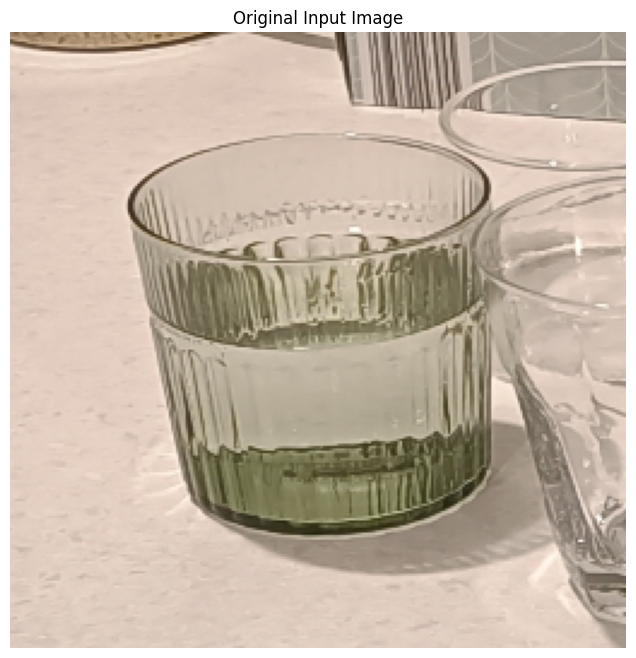

In [89]:
# ==========================================
# 6. Load test image
# ==========================================

if not IMAGE_PATH.exists():
    raise FileNotFoundError(
        f"Test image not found: {IMAGE_PATH}"
    )

image = cv2.imread(str(IMAGE_PATH))

if image is None:
    raise RuntimeError("Could not read image.")

image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB
)

print("Image loaded successfully!")

print("Image dimensions:", image.shape)

plt.figure(figsize=(10, 8))

plt.imshow(image_rgb)

plt.title("Original Input Image")

plt.axis("off")

plt.show()

In [90]:
# ==========================================
# 7. Detect containers
# ==========================================

CONFIDENCE_THRESHOLD = 0.25

container_classes = [39, 40, 41, 45, 75]

results = model.predict(
    source=image,
    conf=CONFIDENCE_THRESHOLD,
    device=device,
    verbose=False
)

result = results[0]

print("Detection completed!")

print("Number of objects detected:", len(result.boxes))

Detection completed!
Number of objects detected: 4


In [91]:
# ==========================================
# 8. Extract container crops
# ==========================================

container_crops = []

container_boxes = []

for box in result.boxes:

    class_id = int(box.cls[0].item())

    if class_id not in container_classes:
        continue

    # Extract bounding box coordinates
    x1, y1, x2, y2 = map(
        int,
        box.xyxy[0].tolist()
    )

    # Keep coordinates inside the image
    height, width = image.shape[:2]

    x1 = max(0, min(x1, width))
    x2 = max(0, min(x2, width))

    y1 = max(0, min(y1, height))
    y2 = max(0, min(y2, height))

    # Extract container image
    crop = image[y1:y2, x1:x2]

    if crop.size == 0:
        continue

    container_crops.append(crop)

    container_boxes.append({
        "class_id": class_id,
        "class_name": model.names[class_id],
        "confidence": float(box.conf[0].item()),
        "bbox": (x1, y1, x2, y2)
    })

    print("\nDetected:", model.names[class_id])

    print(
        "Confidence:",
        round(float(box.conf[0].item()), 3)
    )

    print("Bounding box:", x1, y1, x2, y2)


print("\nTotal containers extracted:", len(container_crops))


Detected: cup
Confidence: 0.72
Bounding box: 48 42 201 210

Detected: cup
Confidence: 0.689
Bounding box: 192 59 255 252

Detected: bowl
Confidence: 0.52
Bounding box: 178 11 255 58

Total containers extracted: 3


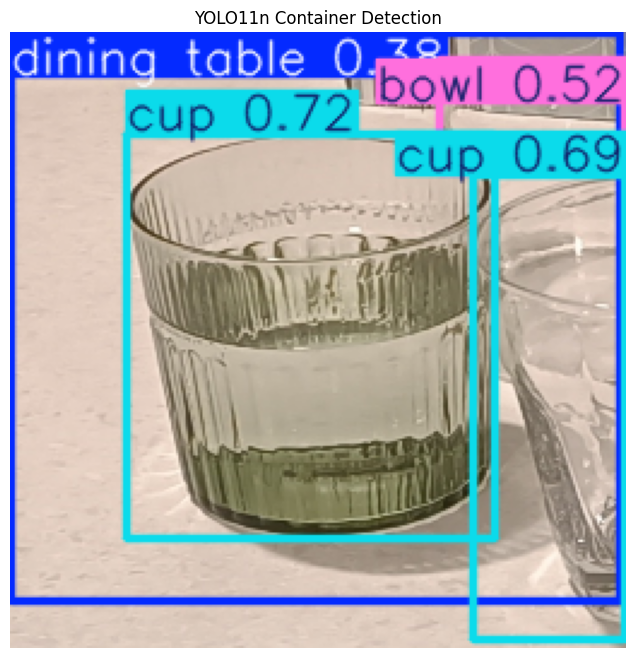

In [92]:
# ==========================================
# 9. Display detection results
# ==========================================

annotated_image = result.plot()

annotated_image_rgb = cv2.cvtColor(
    annotated_image,
    cv2.COLOR_BGR2RGB
)

plt.figure(figsize=(12, 8))

plt.imshow(annotated_image_rgb)

plt.title("YOLO11n Container Detection")

plt.axis("off")

plt.show()

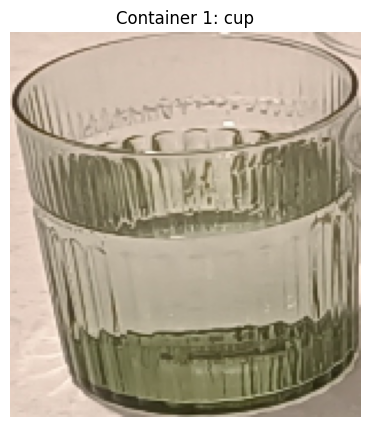

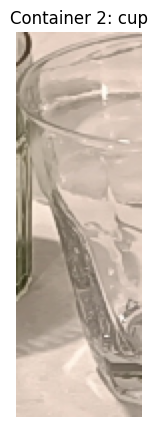

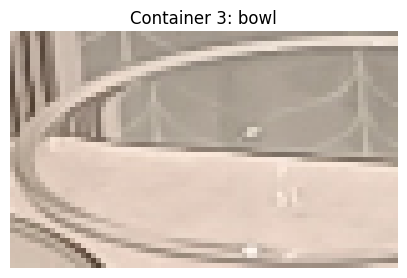

In [93]:
# ==========================================
# 10. Display individual container crops
# ==========================================

if len(container_crops) == 0:

    print("No containers detected.")

else:

    for i, crop in enumerate(container_crops):

        crop_rgb = cv2.cvtColor(
            crop,
            cv2.COLOR_BGR2RGB
        )

        plt.figure(figsize=(5, 5))

        plt.imshow(crop_rgb)

        plt.title(
            f"Container {i + 1}: "
            f"{container_boxes[i]['class_name']}"
        )

        plt.axis("off")

        plt.show()

In [94]:
# ==========================================
# 11. Save output images
# ==========================================

# Save complete annotated image
annotated_path = OUTPUT_DIR / "container_detection.jpg"

cv2.imwrite(
    str(annotated_path),
    annotated_image
)

# Save individual container crops
for i, crop in enumerate(container_crops):

    crop_path = OUTPUT_DIR / f"container_{i + 1}.jpg"

    cv2.imwrite(
        str(crop_path),
        crop
    )

print("Images saved successfully!")

print("Output location:", OUTPUT_DIR)

Images saved successfully!
Output location: C:\Users\wanlo\AI_Vision_Project\output


In [95]:
# ==========================================
# 12. Check SPILL keypoint model
# ==========================================

if not KEYPOINT_MODEL_PATH.exists():

    print("SPILL keypoint checkpoint not found.")

else:

    with open(KEYPOINT_MODEL_PATH, "rb") as f:

        header = f.read(128)

    if header.startswith(
        b"version https://git-lfs.github.com/spec"
    ):

        print("SPILL checkpoint is a Git LFS pointer.")

        print("Actual trained weights have not been downloaded.")

    else:

        print("SPILL keypoint checkpoint file found.")

        print("File size:", KEYPOINT_MODEL_PATH.stat().st_size, "bytes")

SPILL keypoint checkpoint file found.
File size: 70579394 bytes


In [99]:
# ==========================================
# 13. Inspect SPILL repository structure
# ==========================================

from pathlib import Path

print("SPILL repository:", SPILL_DIR)

important_folders = [
    "glassloc",
    "keypoint_detection",
    "checkpoints"
]

for folder in important_folders:

    folder_path = SPILL_DIR / folder

    print(f"\n{folder}/")

    if folder_path.exists():

        for item in folder_path.rglob("*"):

            if item.is_file():
                print("  ", item.relative_to(SPILL_DIR))

    else:

        print("  Folder not found")

SPILL repository: C:\Users\wanlo\Desktop\Beverage_Serving_Robot\SPILL

glassloc/
   glassloc\CameraVisualizer.py
   glassloc\GlassDetector.py
   glassloc\GlassInfo.py
   glassloc\glassloc.py
   glassloc\__init__.py

keypoint_detection/
  Folder not found

checkpoints/
   checkpoints\wild_glasses.ckpt
   checkpoints\yolov8m.pt


In [97]:
from pathlib import Path

SPILL_DIR = Path(
    r"C:\Users\wanlo\Desktop\Beverage_Serving_Robot\SPILL"
)

FILES_TO_INSPECT = [
    "glassloc/GlassDetector.py",
    "glassloc/GlassInfo.py",
    "glassloc/glassloc.py",
    "glassloc/__init__.py",
]

for relative_path in FILES_TO_INSPECT:
    file_path = SPILL_DIR / relative_path

    print("\n" + "=" * 80)
    print(f"FILE: {relative_path}")
    print("=" * 80)

    if file_path.exists():
        print(file_path.read_text(encoding="utf-8"))
    else:
        print("FILE NOT FOUND")


FILE: glassloc/GlassDetector.py
import numpy as np
from airo_camera_toolkit.utils.image_converter import ImageConverter
from ultralytics import YOLO
from typing import List
from airo_typing import OpenCVIntImageType
import torch
from torchvision.transforms.functional import to_tensor

from keypoint_detection.utils.heatmap import get_keypoints_from_heatmap_batch_maxpool
from keypoint_detection.utils.load_checkpoints import get_model_from_wandb_checkpoint, load_from_checkpoint

class GlassDetector:
    def __init__(self, classes: List[str], keypoint_detector: str) -> None:
        self._classes = classes
        self._detector = YOLO("checkpoints/yolov8m.pt")
        self._detector.to("cuda")
        self._keypoint_detector = load_from_checkpoint(keypoint_detector)
        self._keypoint_detector.eval()
        self._keypoint_detector.cuda()

    def get_glass_bounding_boxes(self, image: OpenCVIntImageType) -> np.ndarray | None:
        """Run object detection, detecting glasses ("cup" 

In [98]:
from pathlib import Path

for filename in [
    "requirements.txt",
    "pyproject.toml",
    "setup.py",
    "README.md",
]:
    file_path = SPILL_DIR / filename

    if file_path.exists():
        print("\n" + "=" * 80)
        print(f"FILE: {filename}")
        print("=" * 80)

        content = file_path.read_text(
            encoding="utf-8",
            errors="replace"
        )

        print(content[:12000])


FILE: README.md
# SPILL: Size, Pose, and Internal Liquid Level Estimation of Transparent Glassware for Robotic Bartending

[![HuggingFace Demo](https://img.shields.io/badge/%F0%9F%A4%9D-HuggingFace%20Demo-blue)](https://huggingface.co/spaces/Louadria/SPILL)
[![Dataset](https://img.shields.io/badge/Dataset-Zenodo-green)](https://doi.org/10.5281/zenodo.17288314)

Robotic perception of transparent objects presents unique challenges due to their refractive properties, lack of texture, and limitations of conventional RGB-D sensors in capturing reliable depth information. These challenges significantly hinder robotic manipulation capabilities in real-world settings such as household assistance, hospitality, and healthcare.

To address these issues, we propose **SPILL**: A lightweight perception pipeline for **S**ize, **P**ose, and **I**nternal **L**iquid **L**evel estimation of unknown transparent glassware using a single view. SPILL combines object detection with semantic keypoint detectio